# 2. Tutorial 2

**Course:** High Switching Frequency Power Converters

## 2.1 Output capacitance of a 650 V GaN HEMT

The output capacitance is modelled as $C_\mathrm{oss}(v) = C_\mathrm{lo} + C_\mathrm{hi}\,e^{-v/V_\mathrm{k}}$ (illustrative values).
Following parameters are given:
- $C_\mathrm{lo} = 50~\mathrm{pF}$
- $C_\mathrm{hi} = 434~\mathrm{pF}$
- $V_\mathrm{k} = 83~\mathrm{V}$

The voltage shall be swept in the range [$0 \ldots 400~\mathrm{V}$] with 401 points.

2.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt and scipy.integrate.cumulative_trapezoid) and add constant variables for the constant values.

2.1.2 Create the function `get_C_oss(v)` and compute $Q_\mathrm{oss}(V)$ and $E_\mathrm{oss}(V)$ numerically by cumulative integration of $C_\mathrm{oss}(v)$ and $v\,C_\mathrm{oss}(v)$.

2.1.3 Compute $C_\mathrm{o(tr)} = Q_\mathrm{oss}/V$ and $C_\mathrm{o(er)} = 2E_\mathrm{oss}/V^2$ and plot them together with $C_\mathrm{oss}(v)$ versus $V$ (logarithmic y-axis).

2.1.4 Plot $Q_\mathrm{oss}V$, $2E_\mathrm{oss}$ and $E_\mathrm{oss}$ versus $V$. Print the three values at $400~\mathrm{V}$.


In [1]:
# Subtask 2.1.1 Import necessary modules and add constant variables for the constant values.
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

C_lo = 50e-12     # Unit F
C_hi = 434e-12    # Unit F
V_k = 83          # Unit V
v = np.linspace(0, 400, 401)   # Unit V


# Subtask 2.1.2 C_oss(v), Q_oss(V) and E_oss(V)
def get_C_oss(v):
    """Small-signal output capacitance in F."""
    return C_lo + C_hi * np.exp(-v / V_k)


Q_oss = cumulative_trapezoid(get_C_oss(v), v, initial=0)        # Unit C
E_oss = cumulative_trapezoid(v * get_C_oss(v), v, initial=0)    # Unit J

# Subtask 2.1.3 Equivalent capacitances (skip V = 0)
C_o_tr = Q_oss[1:] / v[1:]
C_o_er = 2 * E_oss[1:] / v[1:]**2
print(f"At 400 V: C_oss = {get_C_oss(400)*1e12:.1f} pF, C_o(tr) = {C_o_tr[-1]*1e12:.1f} pF, "
      f"C_o(er) = {C_o_er[-1]*1e12:.1f} pF")


At 400 V: C_oss = 53.5 pF, C_o(tr) = 139.3 pF, C_o(er) = 85.6 pF


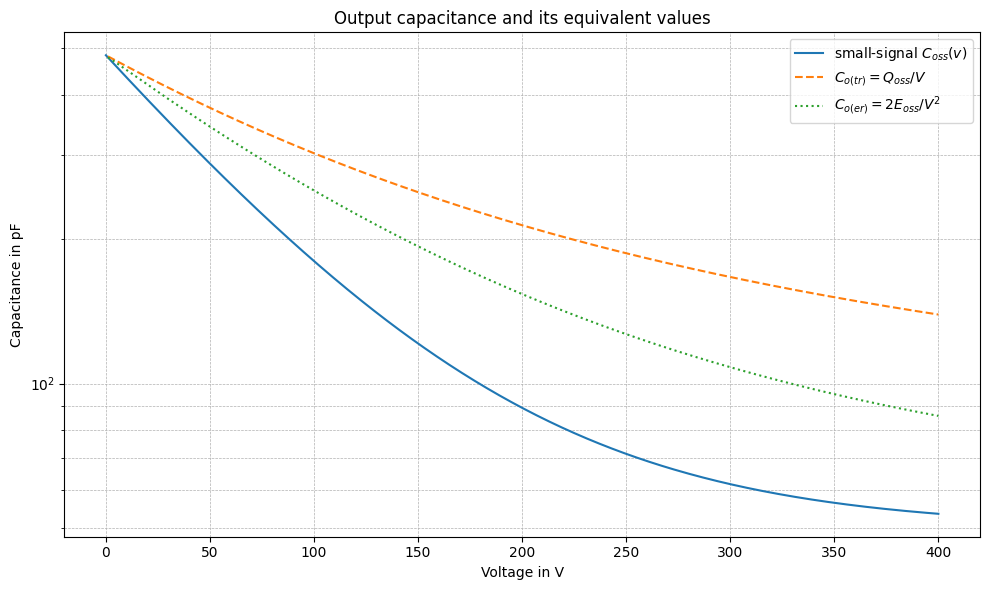

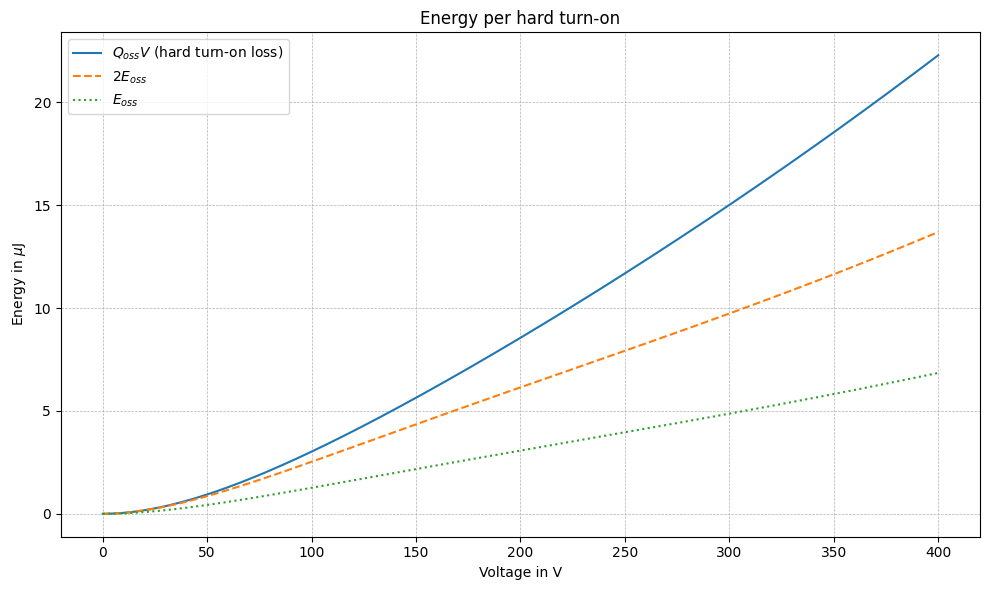

At 400 V: Q_oss*V = 22.29 uJ, 2E_oss = 13.70 uJ, E_oss = 6.85 uJ


In [2]:
if __name__ == "__main__":
    # Subtask 2.1.3 Plot C_oss, C_o(tr) and C_o(er)
    plt.figure(figsize=(10, 6))
    plt.semilogy(v, get_C_oss(v) * 1e12, label='small-signal $C_{oss}(v)$')
    plt.semilogy(v[1:], C_o_tr * 1e12, '--', label='$C_{o(tr)} = Q_{oss}/V$')
    plt.semilogy(v[1:], C_o_er * 1e12, ':', label='$C_{o(er)} = 2E_{oss}/V^2$')
    plt.xlabel('Voltage in V')
    plt.ylabel('Capacitance in pF')
    plt.title('Output capacitance and its equivalent values')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 2.1.4 Hard turn-on loss versus stored energy
    plt.figure(figsize=(10, 6))
    plt.plot(v, Q_oss * v * 1e6, label='$Q_{oss}V$ (hard turn-on loss)')
    plt.plot(v, 2 * E_oss * 1e6, '--', label='$2E_{oss}$')
    plt.plot(v, E_oss * 1e6, ':', label='$E_{oss}$')
    plt.xlabel('Voltage in V')
    plt.ylabel(r'Energy in $\mu$J')
    plt.title('Energy per hard turn-on')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(f"At 400 V: Q_oss*V = {Q_oss[-1]*400*1e6:.2f} uJ, 2E_oss = {2*E_oss[-1]*1e6:.2f} uJ, "
          f"E_oss = {E_oss[-1]*1e6:.2f} uJ")


## 2.2 Loss engine for a hard-switched half-bridge

Build a loss engine for the synchronous buck converter of Task 2.2 of the exercise sheet:
- $V_\mathrm{in} = 48~\mathrm{V}$, $V_\mathrm{o} = 12~\mathrm{V}$, $I_\mathrm{o} = 10~\mathrm{A}$, $T_\mathrm{j} = 100~^\circ\mathrm{C}$

Device data:

| Parameter | GaN | Si |
|---|---|---|
| $R_\mathrm{DS(on)}$ at $25~^\circ\mathrm{C}$ | $5~\mathrm{m\Omega}$ | $5~\mathrm{m\Omega}$ |
| factor at $100~^\circ\mathrm{C}$ | 1.5 | 1.6 |
| $Q_\mathrm{oss}$ at $48~\mathrm{V}$ | $25~\mathrm{nC}$ | $60~\mathrm{nC}$ |
| $t_\mathrm{r}+t_\mathrm{f}$ | $4~\mathrm{ns}$ | $15~\mathrm{ns}$ |
| $Q_\mathrm{rr}$ | $0$ | $60~\mathrm{nC}$ |
| $Q_\mathrm{G}$, $V_\mathrm{dr}$ | $7~\mathrm{nC}$, $5~\mathrm{V}$ | $35~\mathrm{nC}$, $10~\mathrm{V}$ |
| $V_\mathrm{SD}$ | $1.8~\mathrm{V}$ | $0.9~\mathrm{V}$ |
| $t_\mathrm{d}$ | $5~\mathrm{ns}$ | $20~\mathrm{ns}$ |

2.2.1 Create a dictionary `Devices` with the keys 'GaN' and 'Si'. Assign to each key an inner dictionary with the device data.

2.2.2 Create the function `get_losses(dev, f_sw)` which returns a dictionary with the loss terms conduction, capacitive ($Q_\mathrm{oss}V_\mathrm{in}f_\mathrm{sw}$), overlap, reverse recovery, dead time and gate drive.

2.2.3 Print the loss budget and the efficiency of both devices at $1~\mathrm{MHz}$ and show it as a stacked bar chart.

2.2.4 Plot the total loss of both devices versus $f_\mathrm{sw}$ in the range [$10~\mathrm{kHz} \ldots 10~\mathrm{MHz}$] in a log-log diagram.


In [3]:
# Subtask 2.2.1 Device dictionary
V_in, V_o, I_o = 48, 12, 10      # Unit V, V, A
P_o = V_o * I_o                  # Unit W

Devices = {
    'GaN': {'R_25': 5e-3, 'k_T': 1.5, 'Q_oss': 25e-9, 't_rf': 4e-9, 'Q_rr': 0.0,
            'Q_G': 7e-9, 'V_dr': 5, 'V_SD': 1.8, 't_d': 5e-9},
    'Si':  {'R_25': 5e-3, 'k_T': 1.6, 'Q_oss': 60e-9, 't_rf': 15e-9, 'Q_rr': 60e-9,
            'Q_G': 35e-9, 'V_dr': 10, 'V_SD': 0.9, 't_d': 20e-9},
}


# Subtask 2.2.2 Loss terms of the hard-switched buck converter
def get_losses(dev, f_sw):
    """Loss terms in W; the high-side switch turns on hard once per period."""
    return {
        'conduction': I_o**2 * dev['R_25'] * dev['k_T'],
        'capacitive': dev['Q_oss'] * V_in * f_sw,
        'overlap': 0.5 * V_in * I_o * dev['t_rf'] * f_sw,
        'reverse recovery': dev['Q_rr'] * V_in * f_sw,
        'dead time': 2 * dev['V_SD'] * I_o * dev['t_d'] * f_sw,
        'gate drive': 2 * dev['Q_G'] * dev['V_dr'] * f_sw,
    }


# Subtask 2.2.3 Budget at 1 MHz
for name, dev in Devices.items():
    losses = get_losses(dev, 1e6)
    total = sum(losses.values())
    print(name, {k: round(val, 2) for k, val in losses.items()},
          f"total = {total:.2f} W, efficiency = {100 * P_o / (P_o + total):.1f} %")


GaN {'conduction': 0.75, 'capacitive': 1.2, 'overlap': 0.96, 'reverse recovery': 0.0, 'dead time': 0.18, 'gate drive': 0.07} total = 3.16 W, efficiency = 97.4 %
Si {'conduction': 0.8, 'capacitive': 2.88, 'overlap': 3.6, 'reverse recovery': 2.88, 'dead time': 0.36, 'gate drive': 0.7} total = 11.22 W, efficiency = 91.4 %


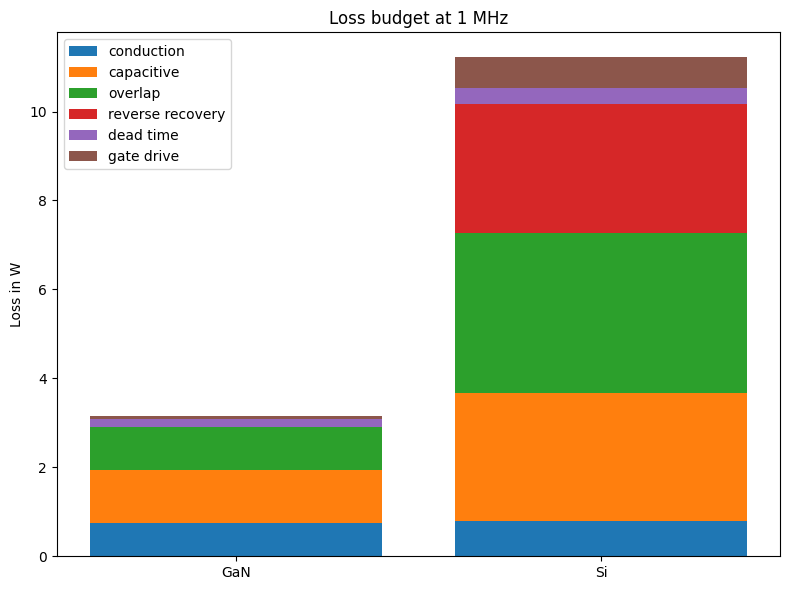

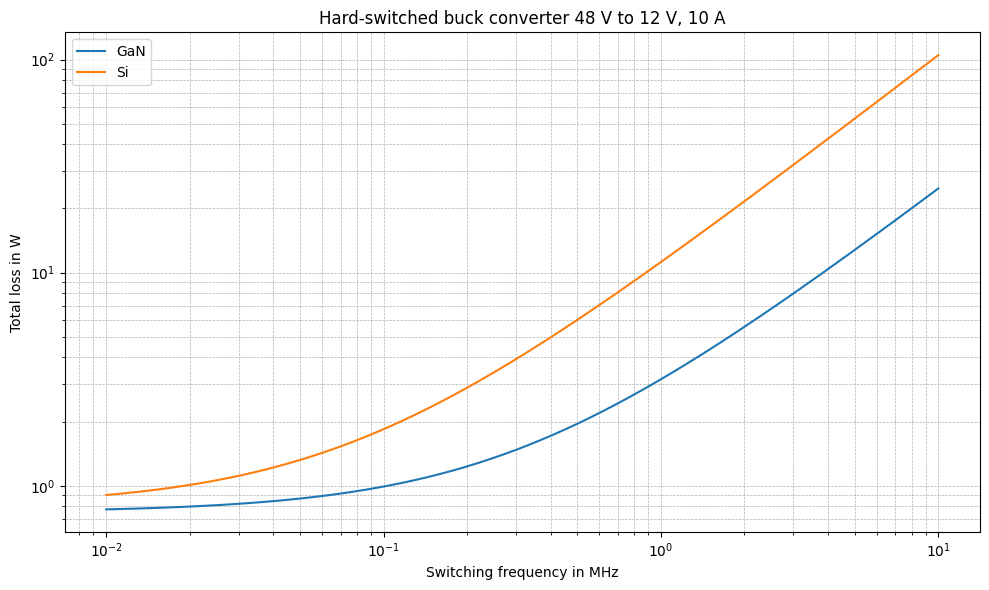

In [4]:
if __name__ == "__main__":
    # Subtask 2.2.3 Stacked bar chart at 1 MHz
    plt.figure(figsize=(8, 6))
    bottom = np.zeros(len(Devices))
    terms = list(get_losses(Devices['GaN'], 1e6).keys())
    for term in terms:
        values = np.array([get_losses(dev, 1e6)[term] for dev in Devices.values()])
        plt.bar(list(Devices.keys()), values, bottom=bottom, label=term)
        bottom += values
    plt.ylabel('Loss in W')
    plt.title('Loss budget at 1 MHz')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 2.2.4 Total loss versus frequency
    f_range = np.logspace(4, 7, 200)
    plt.figure(figsize=(10, 6))
    for name, dev in Devices.items():
        total = sum(get_losses(dev, f_range).values())
        plt.loglog(f_range / 1e6, total, label=name)
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel('Total loss in W')
    plt.title('Hard-switched buck converter 48 V to 12 V, 10 A')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 2.2.4 Solution Comparison

At $1~\mathrm{MHz}$ the GaN design loses $3.16~\mathrm{W}$ ($\eta = 97.4~\%$) and the Si design $11.2~\mathrm{W}$ ($\eta = 91.4~\%$). In the Si design the reverse recovery and the overlap loss alone exceed the total GaN loss. The GaN design reaches the Si loss only at about $4.3~\mathrm{MHz}$.


## 2.3 Optimum die size

Scale the GaN device with the relative die area $a$: $R_\mathrm{DS(on)} = R_1/a$, switching energy per period $E_1 a$, with $I_\mathrm{rms} = 10~\mathrm{A}$, $R_1 = 5~\mathrm{m\Omega}$, $E_1 = 2.41~\mathrm{\mu J}$.

2.3.1 Plot the device loss versus $a$ in the range [$0.1 \ldots 3$] for $f_\mathrm{sw} = 0.25$, $1$ and $4~\mathrm{MHz}$ and mark the minima.

2.3.2 Compare the numerical minima with $a_\mathrm{opt} = I_\mathrm{rms}\sqrt{R_1/(E_1 f_\mathrm{sw})}$ and $P_\mathrm{min} = 2 I_\mathrm{rms}\sqrt{R_1 E_1 f_\mathrm{sw}}$.

2.3.3 Plot $P_\mathrm{min}$ versus $f_\mathrm{sw}$ in a log-log diagram. Which slope do you expect?


f = 0.25 MHz: numerical a = 0.911, P = 1.098 W; analytical a_opt = 0.911, P_min = 1.098 W
f = 1.00 MHz: numerical a = 0.455, P = 2.195 W; analytical a_opt = 0.455, P_min = 2.195 W
f = 4.00 MHz: numerical a = 0.228, P = 4.391 W; analytical a_opt = 0.228, P_min = 4.391 W


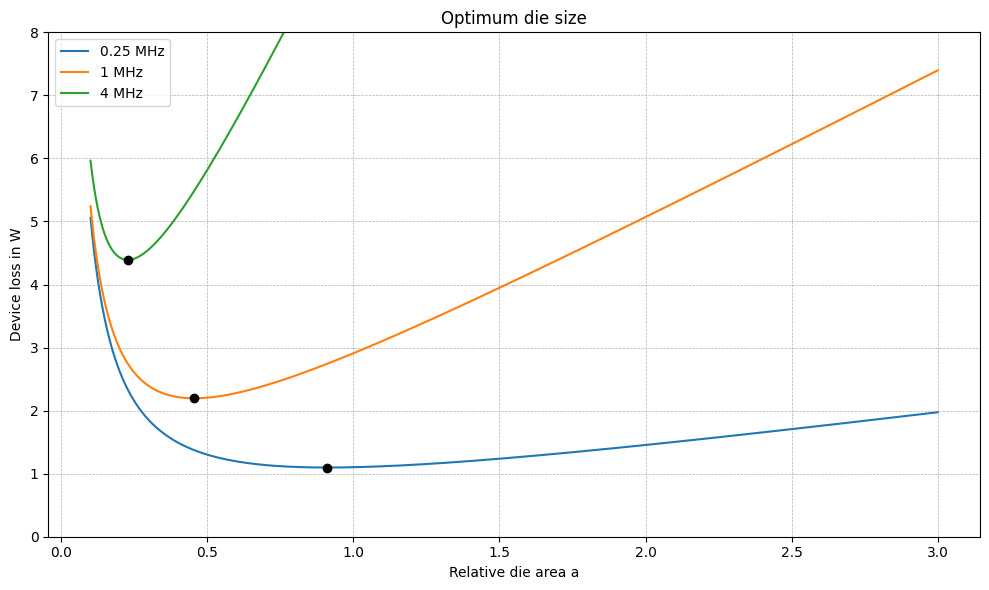

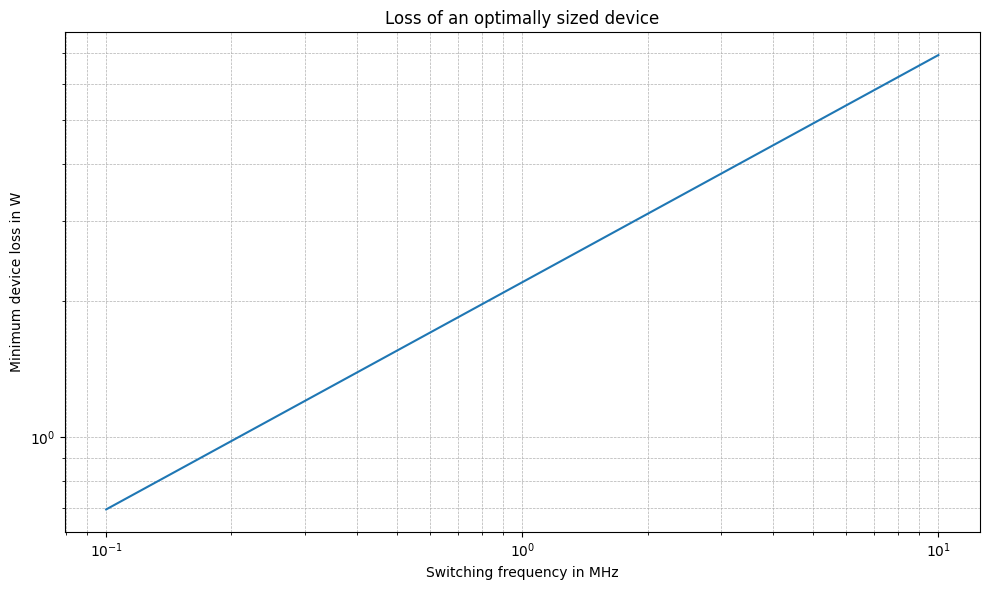

In [5]:
# Subtask 2.3.1 Device loss versus relative die area
I_rms, R_1, E_1 = 10, 5e-3, 2.41e-6
a = np.linspace(0.1, 3, 2901)

if __name__ == "__main__":
    plt.figure(figsize=(10, 6))
    for f in [0.25e6, 1e6, 4e6]:
        P = I_rms**2 * R_1 / a + E_1 * a * f
        i = np.argmin(P)
        plt.plot(a, P, label=f'{f/1e6:g} MHz')
        plt.plot(a[i], P[i], 'ko')
        # Subtask 2.3.2 Compare with the analytical optimum
        a_opt = I_rms * np.sqrt(R_1 / (E_1 * f))
        P_min = 2 * I_rms * np.sqrt(R_1 * E_1 * f)
        print(f"f = {f/1e6:4.2f} MHz: numerical a = {a[i]:.3f}, P = {P[i]:.3f} W; "
              f"analytical a_opt = {a_opt:.3f}, P_min = {P_min:.3f} W")
    plt.ylim(0, 8)
    plt.xlabel('Relative die area a')
    plt.ylabel('Device loss in W')
    plt.title('Optimum die size')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 2.3.3 Minimum loss versus frequency
    f_range = np.logspace(5, 7, 100)
    plt.figure(figsize=(10, 6))
    plt.loglog(f_range / 1e6, 2 * I_rms * np.sqrt(R_1 * E_1 * f_range))
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel('Minimum device loss in W')
    plt.title('Loss of an optimally sized device')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.show()


### 2.3.3 Solution Slope

$P_\mathrm{min} \propto \sqrt{f_\mathrm{sw}}$: in the log-log diagram the line has the slope $1/2$, i.e. ten times the frequency gives $\sqrt{10} = 3.16$ times the loss. At the optimum, conduction and switching loss are equal.


## 2.4 Output capacitance losses under soft switching

Use the fit $E_\mathrm{diss} = k f^{\alpha} V_\mathrm{pp}^{\beta}$ with $k = 2.84\cdot 10^{-10}$, $\alpha = 0.6$, $\beta = 1.70$ ($E_\mathrm{diss}$ in $\mathrm{\mu J}$, $f$ in Hz, $V_\mathrm{pp}$ in V) for a 650 V GaN HEMT (Zulauf et al., IEEE TPEL, 2018). The fit was obtained between 5 and 35 MHz.

2.4.1 Create the function `get_P_coss(f, V_pp)` which returns the power loss in W.

2.4.2 Plot the loss versus frequency in the range [$5 \ldots 35~\mathrm{MHz}$] for $V_\mathrm{pp} = 200$, $400$ and $650~\mathrm{V}$. Add the conduction loss of $3~\mathrm{A}$ rms in $100~\mathrm{m\Omega}$ for comparison.

2.4.3 Above which frequency does the $C_\mathrm{oss}$ loss exceed this conduction loss at $400~\mathrm{V}$?


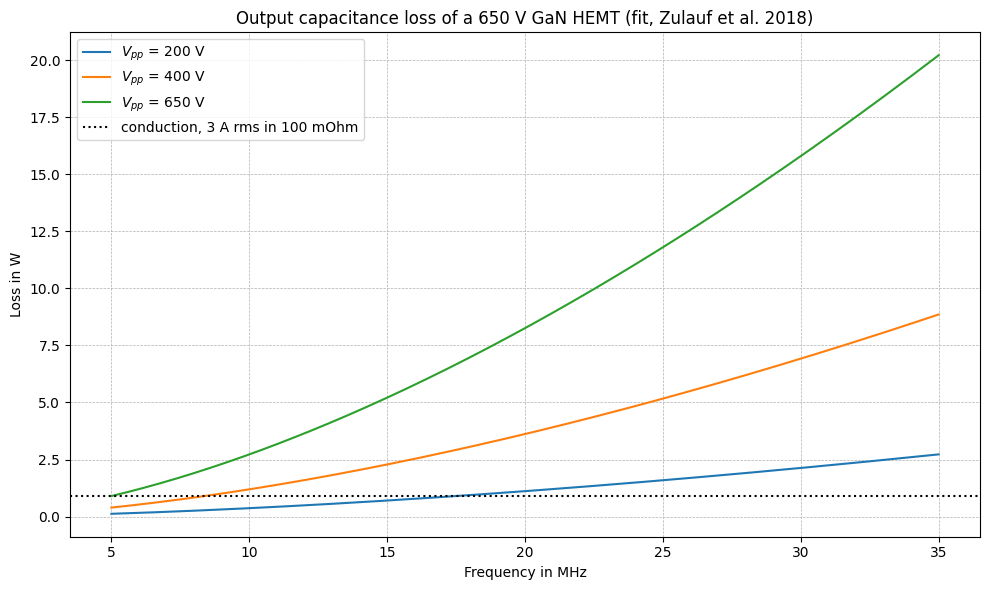

C_oss loss = conduction loss at 8.4 MHz (400 V)


In [6]:
# Subtask 2.4.1 C_oss loss from the Steinmetz-type fit
k, alpha, beta = 2.84e-10, 0.6, 1.70


def get_P_coss(f, V_pp):
    """Power loss in W; the fit returns the energy per cycle in uJ."""
    return k * f**alpha * V_pp**beta * 1e-6 * f


if __name__ == "__main__":
    # Subtask 2.4.2 Loss versus frequency
    f_range = np.linspace(5e6, 35e6, 200)
    P_cond = 3**2 * 0.1
    plt.figure(figsize=(10, 6))
    for V_pp in [200, 400, 650]:
        plt.plot(f_range / 1e6, get_P_coss(f_range, V_pp), label=f'$V_{{pp}}$ = {V_pp} V')
    plt.axhline(P_cond, color='black', linestyle=':', label='conduction, 3 A rms in 100 mOhm')
    plt.xlabel('Frequency in MHz')
    plt.ylabel('Loss in W')
    plt.title('Output capacitance loss of a 650 V GaN HEMT (fit, Zulauf et al. 2018)')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 2.4.3 Frequency at which the C_oss loss equals the conduction loss at 400 V
    f_eq = (P_cond / (k * 400**beta * 1e-6))**(1 / (1 + alpha))
    print(f"C_oss loss = conduction loss at {f_eq/1e6:.1f} MHz (400 V)")


### 2.4.3 Solution

At $400~\mathrm{V}$ the $C_\mathrm{oss}$ loss exceeds $0.9~\mathrm{W}$ above about $8.4~\mathrm{MHz}$, at $650~\mathrm{V}$ above $5~\mathrm{MHz}$ and at $200~\mathrm{V}$ above $17.5~\mathrm{MHz}$. Since the loss rises with $f^{1.6}$, it becomes the dominant device loss in HF and VHF converters.
